# Annotate PPI scores with ClinVar annotations

In [9]:
import polars as pl
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import sys

sys.path.append("../../../1_allele_collection/2_analysis")
from plot_utils import *

sys.path.append("../..")
from analyses_plot_utils import *

In [2]:
sqy2h_outputs_dir = "../3_outputs/sqY2H"
metadata_outputs_dir = "../../../1_allele_collection/3_outputs"
integrative_inputs = "../../../3_integrated_assay_results/1_inputs"

In [17]:
# process metadata
metadata = pl.DataFrame(pd.read_csv(f"{metadata_outputs_dir}/varchamp_seq_confirm_alleles_clinvar_gnomad.tsv", sep="\t"))
mut_cols = ["mutation_id_rc4", "mutation_id_cegs2", "mutation_id_edgotyping3"]
id_vars = [col for col in metadata.columns if col not in mut_cols]
# metadata = metadata.unpivot(index=id_vars, 
#                             on=mut_cols,
#                             variable_name="mutation_collection",
#                             value_name="mut_id")

priority_col = ["orf_id", "mut_id", "symbol", "aa_change", "ensembl_gene_id", "clinvar_clnsig_clean", "gnomad_af", "StarStatus"]
metadata = metadata.select(priority_col).filter(~pl.col("mut_id").is_null()).with_columns(
    pl.col("mut_id").cast(pl.Int64).alias("mut_id"),
    pl.col("orf_id").cast(pl.Int64).alias("orf_id")
)

In [18]:
# merge scores with metadata
scores = pl.read_csv(f"{sqy2h_outputs_dir}/5_variant_perturbation_scores.csv").with_columns(
    pl.col("db_orf_id").cast(pl.Int64).alias("orf_id"),
    pl.col("db_mut_id").cast(pl.Int64).alias("mut_id"),
).drop(["db_orf_id", "db_mut_id"])

scores = scores.join(metadata, on=["orf_id", "mut_id"])
scores.write_csv(f"{sqy2h_outputs_dir}/6_variant_perturbation_scores_annotated.csv")
scores.write_csv(f"{integrative_inputs}/ppi_scores.csv")
# scores = scores.filter(pl.col("clinvar_clnsig_clean") != "5_Others")
scores

euclid_distance,cosine_distance,num_edges,num_zero_wt,num_per_0.0,num_per_0.1,num_per_0.2,num_per_0.3,num_per_0.4,num_per_0.5,num_edge_0.0,num_edge_0.1,num_edge_0.2,num_edge_0.3,num_edge_0.4,num_edge_0.5,frac_per_0.0,frac_per_0.1,frac_per_0.2,frac_per_0.3,frac_per_0.4,frac_per_0.5,normalized_euclid_distance,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,orf_id,mut_id,symbol_right,aa_change_right,ensembl_gene_id_right,clinvar_clnsig_clean_right,gnomad_af_right,StarStatus_right
f64,f64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64,str,str,str,str,str,str,f64,f64,str,i64,i64,str,str,str,str,f64,f64
0.1875,0.0,1,0,0,0,0,0,0,0,1,1,1,1,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.1875,"""EZH2""","""Arg684Cys""","""2050C>T""","""ENSG00000106462""","""CEGS2""","""1_Pathogenic""",null,2.0,"""EZH2_Arg684Cys""",143,213584,"""EZH2""","""Arg684Cys""","""ENSG00000106462""","""1_Pathogenic""",null,2.0
0.0625,0.0,1,0,0,0,0,0,0,0,1,1,1,1,0,0,0.0,0.0,0.0,0.0,null,null,0.0625,"""PTS""","""Arg25Gln""","""74G>A""","""ENSG00000150787""","""CEGS2""","""1_Pathogenic""",6.9900e-7,2.0,"""PTS_Arg25Gln""",145,200059,"""PTS""","""Arg25Gln""","""ENSG00000150787""","""1_Pathogenic""",6.9900e-7,2.0
0.125,0.0,1,0,0,0,0,0,0,0,1,1,1,1,0,0,0.0,0.0,0.0,0.0,null,null,0.125,"""PTS""","""Asp116Gly""","""347A>G""","""ENSG00000150787""","""CEGS2""","""3_Conflicting""",0.000004,1.0,"""PTS_Asp116Gly""",145,200065,"""PTS""","""Asp116Gly""","""ENSG00000150787""","""3_Conflicting""",0.000004,1.0
0.1875,1.0,1,0,1,1,0,0,0,0,1,1,0,0,0,0,1.0,1.0,null,null,null,null,0.1875,"""MVK""","""His20Pro""","""59A>C""","""ENSG00000110921""","""Edgotyping3""","""1_Pathogenic""",0.00001,2.0,"""MVK_His20Pro""",281,3,"""MVK""","""His20Pro""","""ENSG00000110921""","""1_Pathogenic""",0.00001,2.0
0.0625,0.0,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0.0,0.0,null,null,null,null,0.0625,"""MVK""","""Ser52Asn""","""155G>A""","""ENSG00000110921""","""Edgotyping3""","""2_Benign""",0.110614,2.0,"""MVK_Ser52Asn""",281,5,"""MVK""","""Ser52Asn""","""ENSG00000110921""","""2_Benign""",0.110614,2.0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
0.9375,1.0,2,0,2,2,2,2,2,2,2,2,2,2,2,2,1.0,1.0,1.0,1.0,1.0,1.0,0.662913,"""KCNJ2""","""Asn318Ser""","""953A>G""","""ENSG00000123700""","""Edgotyping3""","""4_VUS""",0.000018,2.0,"""KCNJ2_Asn318Ser""",100016069,2650,"""KCNJ2""","""Asn318Ser""","""ENSG00000123700""","""4_VUS""",0.000018,2.0
0.9375,1.0,2,0,2,2,2,2,2,2,2,2,2,2,2,2,1.0,1.0,1.0,1.0,1.0,1.0,0.662913,"""KCNJ2""","""Glu349Lys""","""1045G>A""","""ENSG00000123700""","""Edgotyping3""","""3_Conflicting""",0.000013,1.0,"""KCNJ2_Glu349Lys""",100016069,2654,"""KCNJ2""","""Glu349Lys""","""ENSG00000123700""","""3_Conflicting""",0.000013,1.0
0.9375,1.0,2,0,2,2,2,2,2,2,2,2,2,2,2,2,1.0,1.0,1.0,1.0,1.0,1.0,0.662913,"""KCNJ2""","""Thr400Met""","""1199C>T""","""ENSG00000123700""","""Edgotyping3""","""3_Conflicting""",0.000052,1.0,"""KCNJ2_Thr400Met""",100016069,2656,"""KCNJ2""","""Thr400Met""","""ENSG00000123700""","""3_Conflicting""",0.000052,1.0


In [19]:
scores = scores.sort("mut_id", descending=True).unique(subset=["allele_0"], keep="first")
scores

euclid_distance,cosine_distance,num_edges,num_zero_wt,num_per_0.0,num_per_0.1,num_per_0.2,num_per_0.3,num_per_0.4,num_per_0.5,num_edge_0.0,num_edge_0.1,num_edge_0.2,num_edge_0.3,num_edge_0.4,num_edge_0.5,frac_per_0.0,frac_per_0.1,frac_per_0.2,frac_per_0.3,frac_per_0.4,frac_per_0.5,normalized_euclid_distance,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,orf_id,mut_id,symbol_right,aa_change_right,ensembl_gene_id_right,clinvar_clnsig_clean_right,gnomad_af_right,StarStatus_right
f64,f64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64,str,str,str,str,str,str,f64,f64,str,i64,i64,str,str,str,str,f64,f64
1.369306,0.117854,15,0,6,6,6,6,4,3,15,15,15,15,12,10,0.4,0.4,0.4,0.4,0.333333,0.3,0.353553,"""LITAF""","""Ser118Pro""","""352T>C""","""ENSG00000189067""","""Edgotyping3""","""4_VUS""",null,1.0,"""LITAF_Ser118Pro""",52920,2674,"""LITAF""","""Ser118Pro""","""ENSG00000189067""","""4_VUS""",null,1.0
0.0625,0.0,1,0,0,0,0,0,0,0,1,1,1,1,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0625,"""GMPPB""","""Pro22Ser""","""64C>T""","""ENSG00000173540""","""CEGS2""","""1_Pathogenic""",null,null,"""GMPPB_Pro22Ser""",3449,214607,"""GMPPB""","""Pro22Ser""","""ENSG00000173540""","""1_Pathogenic""",6.9927e-7,null
0.534,1.0,2,0,2,2,1,1,1,0,2,2,1,1,1,0,1.0,1.0,1.0,1.0,1.0,null,0.377595,"""TH""","""Arg306His""","""917G>A""","""ENSG00000180176""","""Edgotyping3""","""3_Conflicting""",null,1.0,"""TH_Arg306His""",71892,4004,"""TH""","""Arg306His""","""ENSG00000180176""","""3_Conflicting""",0.0,1.0
1.699035,0.433224,6,0,6,6,6,6,6,5,6,6,6,6,6,5,1.0,1.0,1.0,1.0,1.0,1.0,0.693628,"""STXBP1""","""Asp238Glu""","""714C>A""","""ENSG00000136854""","""Edgotyping3""","""4_VUS""",null,1.0,"""STXBP1_Asp238Glu""",7652,1806,"""STXBP1""","""Asp238Glu""","""ENSG00000136854""","""4_VUS""",null,1.0
0.565962,0.154816,3,0,1,1,0,0,0,0,3,3,1,1,1,1,0.333333,0.333333,0.0,0.0,0.0,0.0,0.326758,"""PKP2""","""Ile377Thr""","""1130T>C""","""ENSG00000057294""","""Edgotyping3""","""4_VUS""",null,2.0,"""PKP2_Ile377Thr""",54308,3084,"""PKP2""","""Ile377Thr""","""ENSG00000057294""","""4_VUS""",0.00001,2.0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
0.225347,0.063671,2,0,1,1,0,0,0,0,2,2,1,1,1,0,0.5,0.5,0.0,0.0,0.0,null,0.159344,"""TH""","""Val468Met""","""1402G>A""","""ENSG00000180176""","""Edgotyping3""","""3_Conflicting""",null,1.0,"""TH_Val468Met""",71892,3996,"""TH""","""Val468Met""","""ENSG00000180176""","""3_Conflicting""",0.000089,1.0
0.1875,1.0,1,0,1,1,0,0,0,0,1,1,0,0,0,0,1.0,1.0,null,null,null,null,0.1875,"""MVK""","""His20Pro""","""59A>C""","""ENSG00000110921""","""Edgotyping3""","""1_Pathogenic""",0.00001,2.0,"""MVK_His20Pro""",281,3,"""MVK""","""His20Pro""","""ENSG00000110921""","""1_Pathogenic""",0.00001,2.0
0.225347,0.000815,4,0,0,0,0,0,0,0,4,4,4,4,4,4,0.0,0.0,0.0,0.0,0.0,0.0,0.112673,"""KRT6A""","""Ile462Asn""","""1385T>A""","""ENSG00000205420""","""CEGS2""","""1_Pathogenic""",null,2.0,"""KRT6A_Ile462Asn""",4870,215289,"""KRT6A""","""Ile462Asn""","""ENSG00000205420""","""1_Pathogenic""",null,2.0


In [5]:
scores_pd = scores.to_pandas()
print(scores_pd['clinvar_clnsig_clean'].value_counts())

clinvar_clnsig_clean
1_Pathogenic     275
4_VUS             97
3_Conflicting     86
2_Benign          34
Name: count, dtype: int64


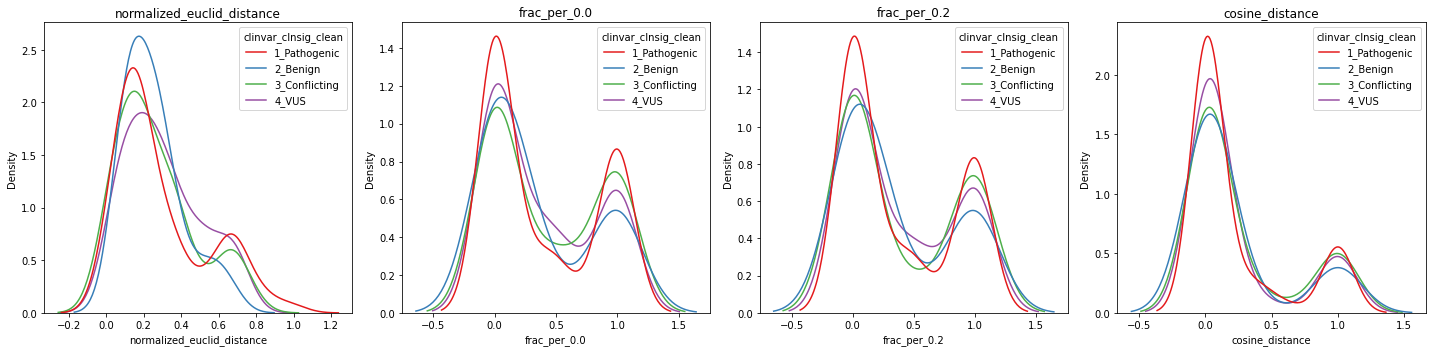

In [11]:
# Define variables to plot
variables = ["normalized_euclid_distance", "frac_per_0.0", "frac_per_0.2", "cosine_distance"]
num_vars = len(variables)

# Create a FacetGrid for multiple subplots
fig, axes = plt.subplots(1, num_vars, figsize=(num_vars*5, 5)) ## , sharey=True
hue_order = sorted(scores["clinvar_clnsig_clean"].drop_nulls().unique().to_list())
# Loop through variables and create subplots
for ax, var in zip(axes, variables):
    sns.kdeplot(
        data=scores,
        x=var,
        hue="clinvar_clnsig_clean",
        hue_order=hue_order,
        ax=ax,
        palette="Set1",
        common_norm=False
    )
    ax.set_title(var)
plt.tight_layout()
plt.show()

(505, 40)
(184, 40)


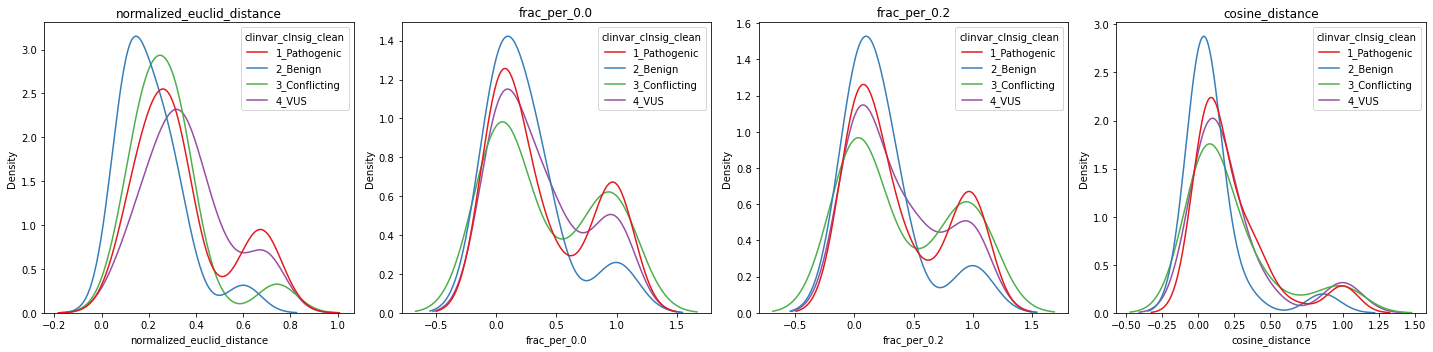

In [13]:
print(scores.shape)
scores_filt = scores.filter(pl.col("num_edges") >= 5)
print(scores_filt.shape)

# Define variables to plot
num_vars = len(variables)

# Create a FacetGrid for multiple subplots
fig, axes = plt.subplots(1, num_vars, figsize=(num_vars*5, 5)) ## , sharey=True
hue_order = sorted(scores_filt["clinvar_clnsig_clean"].drop_nulls().unique().to_list())
# Loop through variables and create subplots
for ax, var in zip(axes, variables):
    sns.kdeplot(
        data=scores_filt,
        x=var,
        hue="clinvar_clnsig_clean",
        hue_order=hue_order,
        ax=ax,
        palette="Set1",
        common_norm=False
    )
    ax.set_title(var)
plt.tight_layout()
plt.show()

(492, 40)
(80, 40)


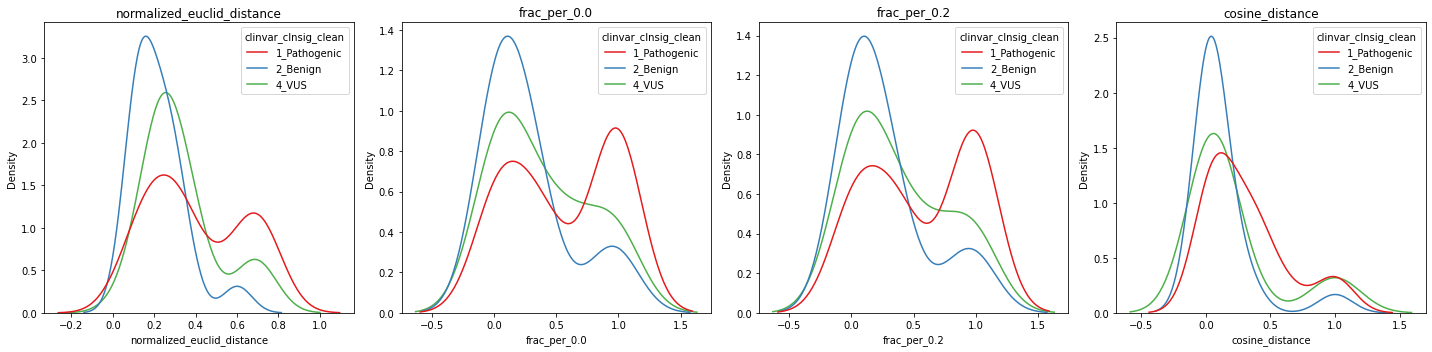

In [12]:
print(scores.shape)
scores_filt = scores.filter(pl.col("num_edges") >= 5).filter(pl.col("StarStatus") >= 2)
print(scores_filt.shape)

# Define variables to plot
num_vars = len(variables)

# Create a FacetGrid for multiple subplots
fig, axes = plt.subplots(1, num_vars, figsize=(num_vars*5, 5)) ## , sharey=True
hue_order = sorted(scores_filt["clinvar_clnsig_clean"].drop_nulls().unique().to_list())
# Loop through variables and create subplots
for ax, var in zip(axes, variables):
    sns.kdeplot(
        data=scores_filt,
        x=var,
        hue="clinvar_clnsig_clean",
        hue_order=hue_order,
        ax=ax,
        palette="Set1",
        common_norm=False
    )
    ax.set_title(var)
plt.tight_layout()
plt.show()

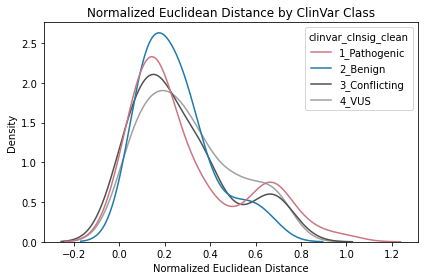

In [10]:
variables = ["normalized_euclid_distance", "frac_per_0.0", "frac_per_0.2", "cosine_distance"]

# Define color mapping for classes
color_map = {
    "1_Pathogenic": "red",
    "2_Benign": "green",
    "3_Conflicting": "orange",
    "4_VUS": "blue"
}

# Only plot the first variable
var = variables[0]
hue_order = ["1_Pathogenic", "2_Benign", "3_Conflicting", "4_VUS"]

sns.kdeplot(
    data=scores,
    x=var,
    hue="clinvar_clnsig_clean",
    hue_order=hue_order,
    # palette=[color_map.get(k, "gray") for k in hue_order],
    palette=palette_dict['clinvar_clnsig_clean'],
    common_norm=False
)

plt.title('Normalized Euclidean Distance by ClinVar Class')
plt.xlabel('Normalized Euclidean Distance')
plt.tight_layout()
plt.show()

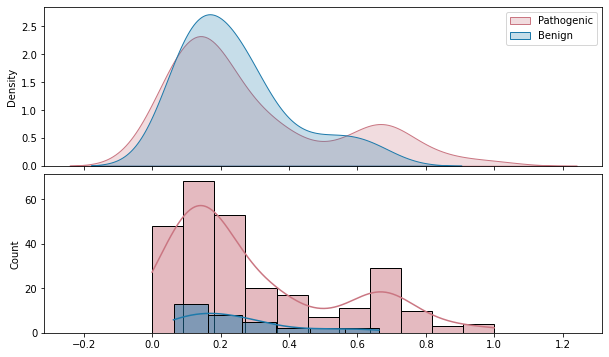

In [21]:

path_thres = 0.42

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
sns.kdeplot(data=scores.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["normalized_euclid_distance"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], fill=True, ax=axes[0])
sns.kdeplot(data=scores.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["normalized_euclid_distance"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], fill=True, ax=axes[0])
# axes[0].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
axes[0].legend()

sns.histplot(scores.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["normalized_euclid_distance"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], kde=True, ax=axes[1])
sns.histplot(scores.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["normalized_euclid_distance"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], kde=True, ax=axes[1])
# axes[1].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
plt.subplots_adjust(hspace=.05)
plt.show()

## LLR calculation

In [23]:

scores.filter(
    pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic", "2_Benign"])
).with_columns(
    pl.when(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")
    .then(pl.lit("Positive"))
    .otherwise(pl.lit("Negative"))
    .alias("referenceSet"),
    pl.col("normalized_euclid_distance").alias("score"),
    pl.col("allele_0").alias("hgvsp")
).select(
    pl.col(["hgvsp", "score", "referenceSet", "normalized_euclid_distance", "allele_0", "clinvar_clnsig_clean"])
).write_csv("../3_outputs/sqY2H/PPI_manual_referenceSet.csv")

scores.with_columns(
    pl.col("normalized_euclid_distance").alias("score"),
    pl.col("allele_0").alias("hgvs_pro")
).select(pl.col(["hgvs_pro", "score"])).write_csv("../3_outputs/sqY2H/PPI_manual_allScores.csv")

In [25]:
%%bash
source /opt/homebrew/Caskroom/miniconda/base/etc/profile.d/conda.sh
conda activate py310

Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_manual_allScores.csv ../3_outputs/sqY2H/PPI_manual_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_manual_LLR_score_bcv" --logfile "../3_outputs/sqY2H/calcLLR/PPI_manual_LLR_bcv.log" --bandwidth "bcv" --printTransitions
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_manual_allScores.csv ../3_outputs/sqY2H/PPI_manual_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_manual_LLR_score_nrd0" --logfile "../3_outputs/sqY2H/calcLLR/PPI_manual_LLR_nrd0.log" --bandwidth "nrd0" --printTransitions
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_manual_allScores.csv ../3_outputs/sqY2H/PPI_manual_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_manual_LLR_score_default" --logfile "../3_outputs/sqY2H/calcLLR/PPI_manual_LLR_default.log" --printTransitions
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_manual_allScores.csv ../3_outputs/sqY2H/PPI_manual_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_manual_LLR_score_nrd" --logfile "../3_outputs/sqY2H/calcLLR/PPI_manual_LLR_nrd.log" --bandwidth "nrd" --printTransitions
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_manual_allScores.csv ../3_outputs/sqY2H/PPI_manual_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_manual_LLR_score_sj" --logfile "../3_outputs/sqY2H/calcLLR/PPI_manual_LLR_sj.log" --printTransitions --bandwidth "SJ"

Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-10-23_14:04:45 INFO: Reading input 
2025-10-23_14:04:45 INFO: Calculating densties 


Error in value[[3L]](cond) : 
  Normalization error: The function will not integrate.Two common causes are: 1.) The kernel is non-smooth, try a smooth kernel if possible. 2.) The supplied support is incorrect.
Calls: buildLLR.kernel ... tryCatch -> tryCatchList -> tryCatchOne -> <Anonymous>


2025-10-23_14:04:46 FATAL: Error in value[[3L]](cond) : 
  Normalization error: The function will not integrate.Two common causes are: 1.) The kernel is non-smooth, try a smooth kernel if possible. 2.) The supplied support is incorrect.
Calls: buildLLR.kernel ... tryCatch -> tryCatchList -> tryCatchOne -> <Anonymous>
 
  


Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


...

Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-10-23_14:04:52 INFO: Reading input 
2025-10-23_14:04:52 INFO: Calculating densties 


Error in value[[3L]](cond) : 
  Normalization error: The function will not integrate.Two common causes are: 1.) The kernel is non-smooth, try a smooth kernel if possible. 2.) The supplied support is incorrect.
Calls: buildLLR.kernel ... tryCatch -> tryCatchList -> tryCatchOne -> <Anonymous>


2025-10-23_14:04:53 FATAL: Error in value[[3L]](cond) : 
  Normalization error: The function will not integrate.Two common causes are: 1.) The kernel is non-smooth, try a smooth kernel if possible. 2.) The supplied support is incorrect.
Calls: buildLLR.kernel ... tryCatch -> tryCatchList -> tryCatchOne -> <Anonymous>
 
  


CalledProcessError: Command 'b'source /opt/homebrew/Caskroom/miniconda/base/etc/profile.d/conda.sh\nconda activate py310\n\nRscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_manual_allScores.csv ../3_outputs/sqY2H/PPI_manual_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_manual_LLR_score_bcv" --logfile "../3_outputs/sqY2H/calcLLR/PPI_manual_LLR_bcv.log" --bandwidth "bcv" --printTransitions\nRscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_manual_allScores.csv ../3_outputs/sqY2H/PPI_manual_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_manual_LLR_score_nrd0" --logfile "../3_outputs/sqY2H/calcLLR/PPI_manual_LLR_nrd0.log" --bandwidth "nrd0" --printTransitions\nRscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_manual_allScores.csv ../3_outputs/sqY2H/PPI_manual_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_manual_LLR_score_default" --logfile "../3_outputs/sqY2H/calcLLR/PPI_manual_LLR_default.log" 

In [26]:
LLR_threshold = 0.676

In [30]:
def plot_patho_benign(scores=None, metric="normalized_euclid_distance", num_edge_filter=1, title=None, threshold=None, fixed_threshold=None, log_treshold=False):
    
    palette_str = "clinvar_clnsig_clean"
    
    palette_dict = {
        "clinvar_clnsig_clean":{
            '1_Pathogenic': "#CA7682",
            '2_Benign': "#1D7AAB",
            '3_Conflicting': "#505050", #"grey", or lighter red "#E6B1B8"
            '4_VUS': "#A0A0A0", ## Pillar default
            '5_Others': "#E0E0E0"
            # '6_No_ClinVar'
        }
    }
    

    if scores is None:
        scores = orf_distances  # This will use the current state of orf_distances
        
    print(f"Plotting {metric} distribution for Pathogenic and Benign variants")
    # total number of variants
    print("Total variants:", scores.shape[0])
    # total number of orf_ids
    print("Total unique orf_id:", scores.select(pl.col("orf_id").n_unique()).item())
    # total number of pathogenic variants
    print("Total Pathogenic variants:", scores.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic").shape[0])
    # total number of benign variants
    print("Total Benign variants:", scores.filter(pl.col("clinvar_clnsig_clean")=="2_Benign").shape[0])
    
    
        
    if threshold:    
        path_thres = scores.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")[metric].max() + 0.016
        print('path_thres:', path_thres)
        if log_treshold:
            path_thres = scores.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")[metric].min() - 0.016
            print('path_thres:', path_thres)
        elif type(threshold) == float or type(threshold) == int:
            path_thres = threshold
            print('path_thres:', path_thres)
        
    if fixed_threshold:
        path_thres = fixed_threshold
        print('fixed_threshold:', path_thres)

    fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
    sns.kdeplot(data=scores.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")[metric].to_numpy(), label='Pathogenic', color=palette_dict[palette_str]["1_Pathogenic"], fill=True, ax=axes[0])
    sns.kdeplot(data=scores.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")[metric].to_numpy(), label='Benign', color=palette_dict[palette_str]["2_Benign"], fill=True, ax=axes[0])
    if threshold:
        axes[0].axvline(x=path_thres, color=palette_dict[palette_str]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
    axes[0].legend()

    sns.histplot(scores.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")[metric].to_numpy(), label='Pathogenic', color=palette_dict[palette_str]["1_Pathogenic"], kde=True, ax=axes[1])
    sns.histplot(scores.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")[metric].to_numpy(), label='Benign', color=palette_dict[palette_str]["2_Benign"], kde=True, ax=axes[1])
    if threshold or fixed_threshold:
        axes[1].axvline(x=path_thres, color=palette_dict[palette_str]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
    plt.subplots_adjust(hspace=.05)
    if title is not None:
        plt.suptitle(title)
    else:
        plt.suptitle(f"Distribution of {metric} scores")
    plt.show()
    
    if num_edge_filter > 1:
        benign_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "2_Benign").filter(pl.col("num_edges") >= num_edge_filter)
        # print(benign_scores.shape)

        path_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "1_Pathogenic").filter(pl.col("num_edges") >= num_edge_filter)
        # print(path_scores.shape)

        vus_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "4_VUS").filter(pl.col("num_edges") >= num_edge_filter)
        # print(vus_scores.shape)

        conf_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "3_Conflicting").filter(pl.col("num_edges") >= num_edge_filter)
        # print(conf_scores.shape)
    else:
        benign_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "2_Benign")
        path_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "1_Pathogenic")
        vus_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "4_VUS")
        conf_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "3_Conflicting")
    if threshold or fixed_threshold:
        if log_treshold:
            print(f"Benign: {benign_scores.filter(pl.col(metric) < path_thres).shape[0]} ({benign_scores.filter(pl.col(metric) < path_thres).shape[0] / benign_scores.shape[0] * 100:.2f}%)")
            print(f"Pathogenic: {path_scores.filter(pl.col(metric) < path_thres).shape[0]} ({path_scores.filter(pl.col(metric) < path_thres).shape[0] / path_scores.shape[0] * 100:.2f}%)")
            print(f"VUS: {vus_scores.filter(pl.col(metric) < path_thres).shape[0]} ({vus_scores.filter(pl.col(metric) < path_thres).shape[0] / vus_scores.shape[0] * 100:.2f}%)")
            print(f"Conflicting: {conf_scores.filter(pl.col(metric) < path_thres).shape[0]} ({conf_scores.filter(pl.col(metric) < path_thres).shape[0] / conf_scores.shape[0] * 100:.2f}%)")
        else:
            print(f"Benign: {benign_scores.filter(pl.col(metric) > path_thres).shape[0]} ({benign_scores.filter(pl.col(metric) > path_thres).shape[0] / benign_scores.shape[0] * 100:.2f}%)")
            print(f"Pathogenic: {path_scores.filter(pl.col(metric) > path_thres).shape[0]} ({path_scores.filter(pl.col(metric) > path_thres).shape[0] / path_scores.shape[0] * 100:.2f}%)")
            print(f"VUS: {vus_scores.filter(pl.col(metric) > path_thres).shape[0]} ({vus_scores.filter(pl.col(metric) > path_thres).shape[0] / vus_scores.shape[0] * 100:.2f}%)")
            print(f"Conflicting: {conf_scores.filter(pl.col(metric) > path_thres).shape[0]} ({conf_scores.filter(pl.col(metric) > path_thres).shape[0] / conf_scores.shape[0] * 100:.2f}%)")
            


# plot_patho_benign()

Plotting normalized_euclid_distance distribution for Pathogenic and Benign variants
Total variants: 530
Total unique orf_id: 76
Total Pathogenic variants: 270
Total Benign variants: 32
fixed_threshold: 0.676


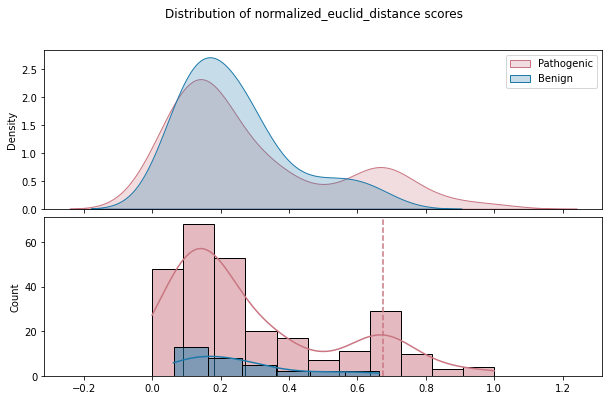

Benign: 0 (0.00%)
Pathogenic: 29 (10.74%)
VUS: 5 (5.21%)
Conflicting: 3 (3.53%)


In [31]:
plot_patho_benign(scores=scores, metric="normalized_euclid_distance", fixed_threshold=LLR_threshold)

## Calculate number of conflicting/VUS that could be reclassified

The normalized scores show good separation. How many alleles would this enable us to putatively reclassify?

(34, 40)
(294, 40)
(92, 40)
(85, 40)


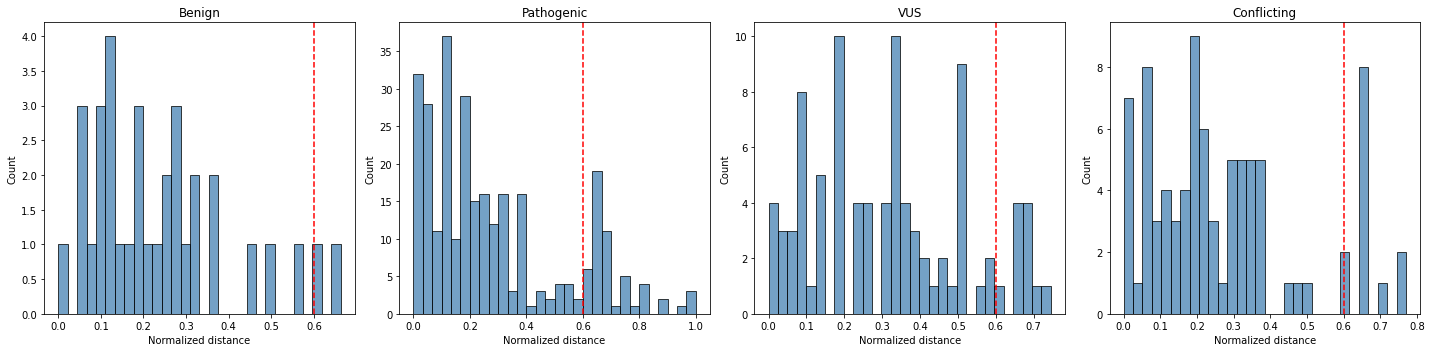

With this threshold, we classify 11 VUS and 12 conflicting alleles as pathogenic at ~5% error rate.


In [15]:
num_edge_filter = 1

benign_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "2_Benign").filter(pl.col("num_edges") >= num_edge_filter)
print(benign_scores.shape)

path_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "1_Pathogenic").filter(pl.col("num_edges") >= num_edge_filter)
print(path_scores.shape)

vus_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "4_VUS").filter(pl.col("num_edges") >= num_edge_filter)
print(vus_scores.shape)

conf_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "3_Conflicting").filter(pl.col("num_edges") >= num_edge_filter)
print(conf_scores.shape)

# Setup subplots
fig, axs = plt.subplots(1, 4, figsize=(20, 5))
plot_data = [
    ("Benign", benign_scores, axs[0]),
    ("Pathogenic", path_scores, axs[1]),
    ("VUS", vus_scores, axs[2]),
    ("Conflicting", conf_scores, axs[3]),
]

# Plot each group
for title, data, ax in plot_data:
    sns.histplot(data=data, x="normalized_euclid_distance", bins=30, color="steelblue", kde=False, ax=ax)
    ax.axvline(0.6, color="red", linestyle="--", linewidth=1.5)
    ax.set_title(title)
    ax.set_xlabel("Normalized distance")
    ax.set_ylabel("Count")
    ax.grid(False)

plt.tight_layout()
plt.show()

print(f"With this threshold, we classify {vus_scores.filter(pl.col('normalized_euclid_distance') > 0.6).shape[0]} VUS and {conf_scores.filter(pl.col('normalized_euclid_distance') > 0.6).shape[0]} conflicting alleles as pathogenic at ~5% error rate.")

# This is ~13.4% of VUS/conflicting

## Consider gnomAD frequency

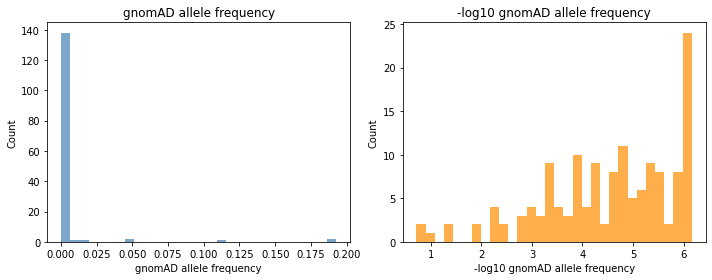

In [16]:
x = scores['gnomad_af']
x = x.filter(x > 0)

y = -np.log10(x.to_numpy())

fig, axs = plt.subplots(1, 2, figsize=(10, 4))

axs[0].hist(x, bins=30, color='steelblue', alpha=0.7)
axs[0].set_title("gnomAD allele frequency")
axs[0].set_xlabel("gnomAD allele frequency")
axs[0].set_ylabel("Count")

axs[1].hist(y, bins=30, color='darkorange', alpha=0.7)
axs[1].set_title("-log10 gnomAD allele frequency")
axs[1].set_xlabel("-log10 gnomAD allele frequency")
axs[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

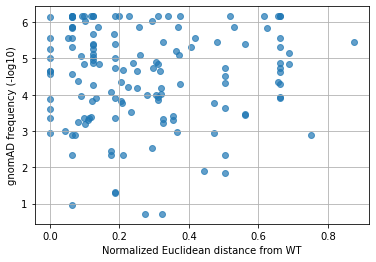

In [17]:
scores = scores.with_columns(
    (-1*pl.col("gnomad_af").log10()).alias("nlog10_gnomad_af")
)

plt.scatter(scores['normalized_euclid_distance'], scores['nlog10_gnomad_af'], alpha=0.7)
plt.ylabel('gnomAD frequency (-log10)')
plt.xlabel('Normalized Euclidean distance from WT')
plt.grid(True)
plt.show()

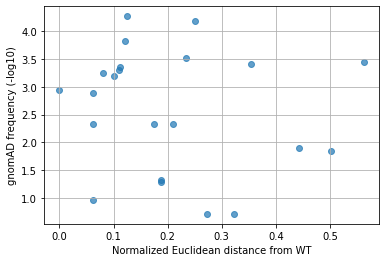

In [18]:
scores_benign = scores.filter(pl.col("clinvar_clnsig_clean") == "2_Benign")

plt.scatter(scores_benign['normalized_euclid_distance'], scores_benign['nlog10_gnomad_af'], alpha=0.7)
plt.ylabel('gnomAD frequency (-log10)')
plt.xlabel('Normalized Euclidean distance from WT')
plt.grid(True)
plt.show()